In [1]:
import logging
import os
import sys
from io import BytesIO
import pandas as pd
import requests
from datetime import date, timedelta, datetime
from collections import Counter
import numpy as np
import json
from astroquery.vizier import Vizier
import astropy.units as u
from astropy.io import fits
from astropy.coordinates import SkyCoord
from tqdm import tqdm
import time
from astropy.table import Table, Column, vstack, join
import re
from astropy.time import Time
from glob import glob
from multiprocessing import Pool

from desispec.io import read_spectra
from desispec.coaddition import coadd_cameras
from desiutil.depend import Dependencies
from scipy.ndimage import gaussian_filter1d

In [2]:
import sys
import numpy as np

sys.path.insert(0, "/pscratch/sd/z/zixinq/timedomain/desitrip/py")

from desitrip.preproc import rebin_flux, rescale_flux

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from glob import glob
import os

prep_out_dir = "/global/cfs/cdirs/desi/users/zixinq/matterhorn_prep_1000"

prep_files = sorted(glob(os.path.join(prep_out_dir, "*_prep_1000.npz")))
print("n prep files:", len(prep_files))
print(prep_files[:3])

In [7]:
d = np.load(prep_files[11], allow_pickle=True)

wave = d["wave_grid"]
X = d["X"]
W = d["W"]
M = d["M"]
targetid = d["TARGETID"]

print("X:", X.shape)
print("W:", W.shape)
print("M:", M.shape)
print("wave:", wave.shape)

X: (500, 1000)
W: (500, 1000)
M: (500, 1000)
wave: (1000,)


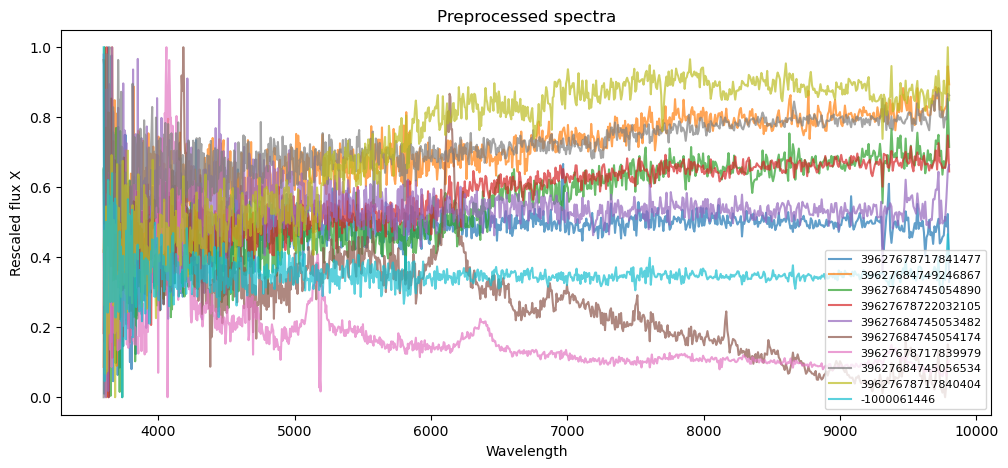

In [8]:
plt.figure(figsize=(12, 5))

for i in range(min(10, len(X))):
    plt.plot(wave, X[i], alpha=0.7, label=str(targetid[i]))

plt.xlabel("Wavelength")
plt.ylabel("Rescaled flux X")
plt.title("Preprocessed spectra")
plt.legend(fontsize=8)
plt.show()

In [1]:
!ls /dvs_ro/cfs/cdirs/desi/public/dr2/spectro/redux/loa/zcatalog/v1

logs				 zpix-sv3-bright.fits
redux_loa_zcatalog_v1.sha256sum  zpix-sv3-dark.fits
zall-pix-loa.fits		 ztile-cmx-other-cumulative.fits
zall-tilecumulative-loa.fits	 ztile-main-backup-cumulative.fits
zpix-cmx-other.fits		 ztile-main-bright-cumulative.fits
zpix-main-backup.fits		 ztile-main-dark-cumulative.fits
zpix-main-bright.fits		 ztile-special-backup-cumulative.fits
zpix-main-dark.fits		 ztile-special-bright-cumulative.fits
zpix-special-backup.fits	 ztile-special-dark-cumulative.fits
zpix-special-bright.fits	 ztile-sv1-backup-cumulative.fits
zpix-special-dark.fits		 ztile-sv1-bright-cumulative.fits
zpix-sv1-backup.fits		 ztile-sv1-dark-cumulative.fits
zpix-sv1-bright.fits		 ztile-sv1-other-cumulative.fits
zpix-sv1-dark.fits		 ztile-sv2-backup-cumulative.fits
zpix-sv1-other.fits		 ztile-sv2-bright-cumulative.fits
zpix-sv2-backup.fits		 ztile-sv2-dark-cumulative.fits
zpix-sv2-bright.fits		 ztile-sv3-backup-cumulative.fits
zpix-sv2-dark.fits		 ztile-sv3-bright-cumulative.fits
zpix-sv3-b

In [1]:
import os, hashlib
import numpy as np
import pandas as pd
from desispec.io import read_spectra
from desispec.coaddition import coadd_cameras


_MASK_CACHE = {}
_CACHE_MAX = 32 

def _cache_get(key):
    return _MASK_CACHE.get(key)

def _cache_put(key, val):
    if key in _MASK_CACHE:
        _MASK_CACHE[key] = val
        return
    if len(_MASK_CACHE) >= _CACHE_MAX:
        _MASK_CACHE.pop(next(iter(_MASK_CACHE)))
    _MASK_CACHE[key] = val

def load_brz_mask_for_path(coadd_path: str):
    cached = _cache_get(coadd_path)
    if cached is not None:
        return cached

    spec = read_spectra(coadd_path)
    co = coadd_cameras(spec)
    band = "brz" if "brz" in co.bands else co.bands[0]

    tids_src = spec.fibermap["TARGETID"].astype(np.int64, copy=False)
    mask_src = co.mask[band].astype(np.int32, copy=False)

    val = (tids_src, mask_src)
    _cache_put(coadd_path, val)
    return val

def add_mask_to_one_brz_npz(npz_path, meta_path, overwrite=False, compress=True):
    d = np.load(npz_path, allow_pickle=True)
    if (not overwrite) and ("mask_brz" in d.files):
        return False

    targetid = d["TARGETID"].astype(np.int64, copy=False)
    wave_brz = d["wave_brz"]
    flux_brz = d["flux_brz"]
    ivar_brz = d["ivar_brz"]
    N, nlam = flux_brz.shape

    meta = pd.read_csv(meta_path).iloc[:N].copy()
    if "COADD_PATH" not in meta.columns:
        raise RuntimeError(f"{meta_path} missing COADD_PATH")
    if "TARGETID" not in meta.columns:
        meta["TARGETID"] = targetid
    meta["TARGETID"] = meta["TARGETID"].astype(np.int64, copy=False)

    mask_out = np.zeros((N, nlam), dtype=np.int32)

    for coadd_path, g in meta.groupby("COADD_PATH", sort=False):
        tids_src, mask_src = load_brz_mask_for_path(coadd_path)

        # vectorized map: tids_need -> indices in tids_src
        tids_need = g["TARGETID"].to_numpy(dtype=np.int64, copy=False)
        dst_rows  = g.index.to_numpy()

        order = np.argsort(tids_src)
        t_sorted = tids_src[order]
        pos = np.searchsorted(t_sorted, tids_need)
        ok = (pos < len(t_sorted)) & (t_sorted[pos] == tids_need)

        mask_out[dst_rows[ok]] = mask_src[order[pos[ok]]]

    # rewrite npz
    save_fn = np.savez_compressed if compress else np.savez
    tmp = npz_path.replace(".npz", ".tmp.npz")
    save_fn(tmp, TARGETID=targetid, wave_brz=wave_brz, flux_brz=flux_brz, ivar_brz=ivar_brz, mask_brz=mask_out)
    os.replace(tmp, npz_path)
    return True


In [1]:
import os, hashlib
import numpy as np
import pandas as pd
from desispec.io import read_spectra
from desispec.coaddition import coadd_cameras

_MASK_CACHE = {}
_CACHE_MAX = 32 

def _cache_get(key):
    return _MASK_CACHE.get(key)

def _cache_put(key, val):
    if key in _MASK_CACHE:
        _MASK_CACHE[key] = val
        return
    if len(_MASK_CACHE) >= _CACHE_MAX:
        _MASK_CACHE.pop(next(iter(_MASK_CACHE)))
    _MASK_CACHE[key] = val

def load_brz_mask_for_path(coadd_path: str):
    """
    Returns tids_src (500,) and mask_brz (500, nlam) for this coadd_path.
    Cached in-process.
    """
    cached = _cache_get(coadd_path)
    if cached is not None:
        return cached

    spec = read_spectra(coadd_path)
    co = coadd_cameras(spec)
    band = "brz" if "brz" in co.bands else co.bands[0]

    tids_src = spec.fibermap["TARGETID"].astype(np.int64, copy=False)
    mask_src = co.mask[band].astype(np.int32, copy=False)

    val = (tids_src, mask_src)
    _cache_put(coadd_path, val)
    return val

def add_mask_to_one_brz_npz(npz_path, meta_path, overwrite=False, compress=True):
    d = np.load(npz_path, allow_pickle=True)
    if (not overwrite) and ("mask_brz" in d.files):
        return False

    targetid = d["TARGETID"].astype(np.int64, copy=False)
    wave_brz = d["wave_brz"]
    flux_brz = d["flux_brz"]
    ivar_brz = d["ivar_brz"]
    N, nlam = flux_brz.shape

    meta = pd.read_csv(meta_path).iloc[:N].copy()
    if "COADD_PATH" not in meta.columns:
        raise RuntimeError(f"{meta_path} missing COADD_PATH")
    if "TARGETID" not in meta.columns:
        meta["TARGETID"] = targetid
    meta["TARGETID"] = meta["TARGETID"].astype(np.int64, copy=False)

    mask_out = np.zeros((N, nlam), dtype=np.int32)

    for coadd_path, g in meta.groupby("COADD_PATH", sort=False):
        tids_src, mask_src = load_brz_mask_for_path(coadd_path)

        # vectorized map: tids_need -> indices in tids_src
        tids_need = g["TARGETID"].to_numpy(dtype=np.int64, copy=False)
        dst_rows  = g.index.to_numpy()

        order = np.argsort(tids_src)
        t_sorted = tids_src[order]
        pos = np.searchsorted(t_sorted, tids_need)
        ok = (pos < len(t_sorted)) & (t_sorted[pos] == tids_need)

        mask_out[dst_rows[ok]] = mask_src[order[pos[ok]]]

    # rewrite npz
    save_fn = np.savez_compressed if compress else np.savez
    tmp = npz_path.replace(".npz", ".tmp.npz")
    save_fn(tmp, TARGETID=targetid, wave_brz=wave_brz, flux_brz=flux_brz, ivar_brz=ivar_brz, mask_brz=mask_out)
    os.replace(tmp, npz_path)
    return True

In [2]:
from glob import glob
from tqdm import tqdm
import os

def patch_directory(brz_dir, pattern="*_brz.npz", compress=True, overwrite=False):
    npzs = sorted(glob(os.path.join(brz_dir, pattern)))
    if not npzs:
        raise RuntimeError(f"No files matched {pattern} in {brz_dir}")

    n_ok = n_skip = n_fail = 0
    for npz_path in tqdm(npzs, desc="Patching mask_brz", unit="file"):
        meta_path = os.path.splitext(npz_path)[0] + "_meta.csv"
        if not os.path.exists(meta_path):
            tqdm.write(f"[skip] missing meta: {os.path.basename(meta_path)}")
            n_skip += 1
            continue
        try:
            updated = add_mask_to_one_brz_npz(npz_path, meta_path, overwrite=overwrite, compress=compress)
            n_ok += int(updated)
            n_skip += int(not updated)
        except Exception as e:
            tqdm.write(f"[fail] {os.path.basename(npz_path)}: {repr(e)}")
            n_fail += 1

    print(f"[done] updated={n_ok} skipped={n_skip} failed={n_fail}")

In [3]:
from concurrent.futures import ProcessPoolExecutor, as_completed
from glob import glob
from tqdm import tqdm
import os

def _patch_one(npz_path, compress=True, overwrite=False):
    meta_path = os.path.splitext(npz_path)[0] + "_meta.csv"
    if not os.path.exists(meta_path):
        return (npz_path, "skip", "missing meta")
    try:
        updated = add_mask_to_one_brz_npz(npz_path, meta_path, overwrite=overwrite, compress=compress)
        return (npz_path, "ok" if updated else "skip", None)
    except Exception as e:
        return (npz_path, "fail", repr(e))

def patch_directory_parallel(brz_dir, pattern="batch_*_brz.npz", compress=True, overwrite=False, max_workers=4):
    npzs = sorted(glob(os.path.join(brz_dir, pattern)))
    if not npzs:
        raise RuntimeError(f"No files matched {pattern} in {brz_dir}")

    n_ok = n_skip = n_fail = 0

    with ProcessPoolExecutor(max_workers=max_workers) as ex:
        futs = [ex.submit(_patch_one, p, compress, overwrite) for p in npzs]
        for fut in tqdm(as_completed(futs), total=len(futs), desc="Patching mask_brz", unit="file"):
            npz_path, status, err = fut.result()
            if status == "ok":
                n_ok += 1
            elif status == "skip":
                n_skip += 1
            else:
                n_fail += 1
                tqdm.write(f"[fail] {os.path.basename(npz_path)}: {err}")

    print(f"[done] updated={n_ok} skipped={n_skip} failed={n_fail}")

In [4]:
brz_dir = "/global/cfs/cdirs/m4237/zixinq/data/dr2_catalog/galaxy_spectra/task_/brz"
patch_directory_parallel(brz_dir, max_workers=4)

Patching mask_brz: 100%|██████████| 856/856 [00:18<00:00, 47.26file/s]

[done] updated=0 skipped=856 failed=0


In [5]:
import numpy as np

p = "/global/cfs/cdirs/m4237/zixinq/data/dr2_catalog/galaxy_spectra/task_/brz/batch_0000_000000_brz.npz"
d = np.load(p)

print("has mask_brz:", "mask_brz" in d.files)
print("keys:", sorted(d.files))



has mask_brz: True
keys: ['TARGETID', 'flux_brz', 'ivar_brz', 'mask_brz', 'wave_brz']
mask shape: (50000, 7781)
unique (first 20): [   0    1    3    4    5   16   17   19  128  129  132  133  144  145
 1024 1025 1040 1041]
frac nonzero: 0.004355486441331448


In [19]:
frac = (d["mask_brz"] != 0).sum(axis=1) / d["mask_brz"].shape[1]

bad_idx = np.where(frac > 0.05)[0]

print("n_bad:", len(bad_idx))


i = bad_idx[100]
print("frac:", frac[i])

import matplotlib.pyplot as plt

flux = d["flux_brz"][i].copy()
mask = d["mask_brz"][i]

flux[mask != 0] = np.nan

plt.figure(figsize=(12,3))
plt.plot(d["wave_brz"], flux)
plt.title(f"masked spectrum frac={frac[i]:.3f}")
plt.show()

n_bad: 36


IndexError: index 100 is out of bounds for axis 0 with size 36

In [ ]:
plt.figure(figsize=(12,3))
plt.plot(d["wave_brz"], d["flux_brz"][i])
plt.title(f"masked spectrum frac={frac[i]:.3f}")
plt.show()

In [8]:
!mkdir -p /global/cfs/cdirs/m4237/zixinq/data/dr2_catalog/galaxy_spectra_brz
!rsync -av --info=progress2 /pscratch/sd/z/zixinq/galaxy_spectra_brz/task_/ \
  /global/cfs/cdirs/m4237/zixinq/data/dr2_catalog/galaxy_spectra_brz/

sending incremental file list
./
batch_0000_000000_brz.npz
  3,112,832,214   0%  389.78MB/s    0:00:07 (xfr#1, to-chk=1713/1715)
batch_0000_000000_brz_meta.csv
  3,122,282,406   0%  389.08MB/s    0:00:07 (xfr#2, to-chk=1712/1715)
batch_0000_000001_brz.npz
  6,210,025,452   0%  421.43MB/s    0:00:14 (xfr#3, to-chk=1711/1715)
batch_0000_000001_brz_meta.csv
  6,219,403,554   0%  420.93MB/s    0:00:14 (xfr#4, to-chk=1710/1715)
batch_0000_000002_brz.npz
  9,324,453,768   0%  429.86MB/s    0:00:20 (xfr#5, to-chk=1709/1715)
batch_0000_000002_brz_meta.csv
  9,333,880,283   0%  429.50MB/s    0:00:20 (xfr#6, to-chk=1708/1715)
batch_0000_000003_brz.npz
 12,440,175,617   0%  433.54MB/s    0:00:27 (xfr#7, to-chk=1707/1715)
batch_0000_000003_brz_meta.csv
 12,449,588,265   0%  433.28MB/s    0:00:27 (xfr#8, to-chk=1706/1715)
batch_0000_000004_brz.npz
 15,554,576,223   0%  438.01MB/s    0:00:33 (xfr#9, to-chk=1705/1715)
batch_0000_000004_brz_meta.csv
 15,564,012,326   0%  437.81MB/s    0:00:33 (xfr#10,

In [1]:
import os
import numpy as np
from glob import glob
from tqdm import tqdm
from desitrip.preproc import rebin_flux, rescale_flux

def build_loglam_grid(wave_in, nbins=1000):
    wmin = float(np.nanmin(wave_in))
    wmax = float(np.nanmax(wave_in))
    logmin = np.log10(wmin)
    logmax = np.log10(wmax)
    loglam = np.linspace(logmin, logmax, nbins, dtype=np.float64)
    wave_out = (10**loglam).astype(np.float32)
    return wave_out

def rebin_interp_1d(wave_in, y_in, wave_out):
    good = np.isfinite(y_in) & np.isfinite(wave_in)
    if good.sum() < 2:
        return np.full_like(wave_out, np.nan, dtype=np.float32), np.zeros_like(wave_out, dtype=bool)
    y_out = np.interp(wave_out, wave_in[good], y_in[good], left=np.nan, right=np.nan).astype(np.float32)
    ok = np.isfinite(y_out)
    return y_out, ok

def preprocess_batch_brz(npz_in, npz_out, wave_out=None, nbins=1000, compress=False):
    d = np.load(npz_in, allow_pickle=True)

    targetid = d["TARGETID"].astype(np.int64, copy=False)
    wave_in  = d["wave_brz"].astype(np.float32, copy=False)
    flux_in  = d["flux_brz"].astype(np.float32, copy=False)
    ivar_in  = d["ivar_brz"].astype(np.float32, copy=False)

    N, L = flux_in.shape
    assert ivar_in.shape == (N, L)
    assert wave_in.shape == (L,)

    if wave_out is None:
        wave_out = build_loglam_grid(wave_in, nbins=nbins)
    else:
        wave_out = np.asarray(wave_out, dtype=np.float32)
        nbins = len(wave_out)

    wmin = float(np.nanmin(wave_in))
    wmax = float(np.nanmax(wave_in))

    X = np.empty((N, nbins), dtype=np.float32)
    W = np.empty((N, nbins), dtype=np.float32)
    M = np.empty((N, nbins), dtype=np.uint8)
    norm = np.empty(N, dtype=np.float32)

    for i in range(N):
        f = flux_in[i]
        w = ivar_in[i]

        bad = (~np.isfinite(f)) | (~np.isfinite(w)) | (w <= 0)

        f2 = f.copy()
        w2 = w.copy()
        f2[bad] = np.nan
        w2[bad] = np.nan

        # rebin
        rewave, reflux, reivar = rebin_flux(wave / (z + 1), flux, ivar, minwave=wmin, maxwave=wmax, nbins=1000, log=True, clip=True)

        # normalization
        if valid.any():
            s = np.nanpercentile(np.abs(f_out[valid]), 75)
            if not np.isfinite(s) or s <= 0:
                s = 1.0
        else:
            s = 1.0

        f_norm = f_out / s
        w_norm = w_out * (s ** 2)

        #w_norm = np.clip(w_norm, 0.0, 1e4)

        X[i] = np.where(valid, f_norm, 0.0).astype(np.float32)
        W[i] = np.where(valid, w_norm, 0.0).astype(np.float32)
        M[i] = valid.astype(np.uint8)
        norm[i] = np.float32(s)

    #keep valid fraction and s/n
    valid_frac = M.mean(axis=1).astype(np.float32)

    snr_proxy = np.zeros(N, dtype=np.float32)
    for j in range(N):
        valid = M[j] > 0
        if valid.any():
            snr_proxy[j] = np.nanmedian(np.abs(X[j, valid]) * np.sqrt(W[j, valid]))
        else:
            snr_proxy[j] = 0.0

    keep_train = ((valid_frac >= 0.9) & (snr_proxy >= 3.0)).astype(np.uint8)

    os.makedirs(os.path.dirname(npz_out) or ".", exist_ok=True)
    save_fn = np.savez_compressed if compress else np.savez
    tmp = npz_out.replace(".npz", ".tmp.npz")
    save_fn(
        tmp,
        TARGETID=targetid,
        wave_grid=wave_out,
        X=X,
        W=W,
        M=M,
        norm=norm,
        valid_frac=valid_frac,
        snr_proxy=snr_proxy,
        keep_train=keep_train,
    )
    os.replace(tmp, npz_out)
    
def preprocess_dir(brz_dir, out_dir, nbins=1000, compress=False, skip_existing=True):
    os.makedirs(out_dir, exist_ok=True)
    files = sorted(glob(os.path.join(brz_dir, "*_brz.npz")))
    print("Found", len(files), "brz files")

    for f in tqdm(files, desc="preprocess", unit="file"):
        base = os.path.basename(f).replace("_brz.npz", "")
        out = os.path.join(out_dir, base + f"_prep_{nbins}.npz")
        if skip_existing and os.path.exists(out):
            continue
        preprocess_batch_brz(f, out, nbins=nbins, compress=compress)

In [2]:
import os
from glob import glob

import numpy as np
from tqdm import tqdm

from desitrip.preproc import rebin_flux, rescale_flux


def preprocess_batch_brz(
    npz_in,
    npz_out,
    nbins=1000,
    minwave=3600.0,
    maxwave=9800.0,
    log=True,
    use_redshift=False,
    redshift_key="Z",
    compress=False,
):
    d = np.load(npz_in, allow_pickle=True)

    targetid = d["TARGETID"].astype(np.int64, copy=False)
    wave_in = d["wave_brz"].astype(np.float32, copy=False)
    flux_in = d["flux_brz"].astype(np.float32, copy=True)
    ivar_in = d["ivar_brz"].astype(np.float32, copy=True)
    spectype = d["SPECTYPE"] if "SPECTYPE" in d else None

    if flux_in.ndim != 2:
        raise ValueError(f"flux_brz must be 2D, got shape {flux_in.shape}")
    if ivar_in.shape != flux_in.shape:
        raise ValueError(f"ivar_brz shape {ivar_in.shape} != flux_brz shape {flux_in.shape}")
    if wave_in.ndim != 1 or wave_in.shape[0] != flux_in.shape[1]:
        raise ValueError(f"wave_brz shape {wave_in.shape} incompatible with flux_brz shape {flux_in.shape}")
    if not np.all(np.isfinite(wave_in)):
        raise ValueError("wave_brz contains non-finite values")
    if not np.all(np.diff(wave_in) > 0):
        raise ValueError("wave_brz must be strictly increasing")

    N, _ = flux_in.shape

    if spectype is not None and len(spectype) != N:
        raise ValueError(f"SPECTYPE length {len(spectype)} != number of spectra {N}")

    if use_redshift:
        if redshift_key not in d:
            raise KeyError(f"use_redshift=True but '{redshift_key}' not found in {npz_in}")
        z_in = d[redshift_key].astype(np.float32, copy=False)
        if z_in.shape[0] != N:
            raise ValueError(f"{redshift_key} length {z_in.shape[0]} != number of spectra {N}")
    else:
        z_in = None

    # Original native-grid S/N without all-NaN warnings
    valid_native = np.isfinite(flux_in) & np.isfinite(ivar_in) & (ivar_in > 0)
    snr_orig = np.zeros(N, dtype=np.float32)
    for i in range(N):
        if np.any(valid_native[i]):
            vals = np.abs(flux_in[i, valid_native[i]]) * np.sqrt(ivar_in[i, valid_native[i]])
            snr_orig[i] = np.float32(np.median(vals))
        else:
            snr_orig[i] = 0.0

    # Sanitize for rebinning
    bad = (~np.isfinite(flux_in)) | (~np.isfinite(ivar_in)) | (ivar_in <= 0)
    flux_in[bad] = 0.0
    ivar_in[bad] = 0.0

    # Keep only rows that rebin_flux batch mode will not drop
    keep_rows = np.count_nonzero(flux_in, axis=1) > 0
    nkeep = int(np.sum(keep_rows))

    # Full-size outputs
    wave_grid = np.logspace(np.log10(minwave), np.log10(maxwave), nbins).astype(np.float32) if log \
        else np.linspace(minwave, maxwave, nbins).astype(np.float32)

    X = np.zeros((N, nbins), dtype=np.float32)
    W = np.zeros((N, nbins), dtype=np.float32)
    M = np.zeros((N, nbins), dtype=np.uint8)
    norm = np.ones(N, dtype=np.float32)

    if nkeep > 0:
        flux_keep = flux_in[keep_rows]
        ivar_keep = ivar_in[keep_rows]
        z_keep = z_in[keep_rows] if z_in is not None else None

        rewave, f_keep, w_keep = rebin_flux(
            wave=wave_in,
            flux=flux_keep,
            ivar=ivar_keep,
            z=z_keep,
            minwave=minwave,
            maxwave=maxwave,
            nbins=nbins,
            log=log,
            clip=False,
        )

        wave_grid = np.asarray(rewave, dtype=np.float32)
        f_keep = np.asarray(f_keep, dtype=np.float32)
        w_keep = np.asarray(w_keep, dtype=np.float32)

        if f_keep.shape != (nkeep, nbins):
            raise ValueError(f"Unexpected rebinned flux shape {f_keep.shape}, expected {(nkeep, nbins)}")
        if w_keep.shape != (nkeep, nbins):
            raise ValueError(f"Unexpected rebinned ivar shape {w_keep.shape}, expected {(nkeep, nbins)}")

        out_rows = np.flatnonzero(keep_rows)

        for j, i in enumerate(out_rows):
            valid = np.isfinite(f_keep[j]) & np.isfinite(w_keep[j]) & (w_keep[j] > 0)
            if not np.any(valid):
                continue

            fv = f_keep[j, valid]
            wv = w_keep[j, valid]

            fmin = np.min(fv)
            fmax = np.max(fv)
            scale = fmax - fmin

            if np.isfinite(scale) and scale > 0:
                X[i, valid] = rescale_flux(fv).astype(np.float32)
                W[i, valid] = (wv * (scale ** 2)).astype(np.float32)
                norm[i] = np.float32(scale)
            else:
                X[i, valid] = 0.0
                W[i, valid] = 0.0
                norm[i] = 1.0

            M[i, valid] = 1

    valid_frac = M.mean(axis=1).astype(np.float32)

    snr_proxy = np.zeros(N, dtype=np.float32)
    for i in range(N):
        valid = M[i] > 0
        if np.any(valid):
            vals = np.abs(X[i, valid]) * np.sqrt(W[i, valid])
            snr_proxy[i] = np.float32(np.median(vals))
        else:
            snr_proxy[i] = 0.0

    keep_train = ((valid_frac >= 0.9) & (snr_orig >= 3.0)).astype(np.uint8)

    os.makedirs(os.path.dirname(npz_out) or ".", exist_ok=True)
    save_fn = np.savez_compressed if compress else np.savez
    tmp = npz_out.replace(".npz", ".tmp.npz")

    save_kwargs = dict(
        TARGETID=targetid,
        wave_grid=wave_grid,
        X=X,
        W=W,
        M=M,
        norm=norm,
        valid_frac=valid_frac,
        snr_orig=snr_orig,
        snr_proxy=snr_proxy,
        keep_train=keep_train,
    )
    if spectype is not None:
        save_kwargs["SPECTYPE"] = spectype

    save_fn(tmp, **save_kwargs)
    os.replace(tmp, npz_out)
    

def preprocess_dir(
    brz_dir,
    out_dir,
    nbins=1000,
    minwave=3600.0,
    maxwave=9800.0,
    log=True,
    use_redshift=False,
    redshift_key="Z",
    compress=False,
    skip_existing=True,
):
    """
    Preprocess all *_brz.npz files in a directory.
    """
    os.makedirs(out_dir, exist_ok=True)
    files = sorted(glob(os.path.join(brz_dir, "*_brz.npz")))
    print(f"Found {len(files)} brz files")

    for f in tqdm(files, desc="preprocess", unit="file"):
        base = os.path.basename(f).replace("_brz.npz", "")
        out = os.path.join(out_dir, f"{base}_prep_{nbins}.npz")
        if skip_existing and os.path.exists(out):
            continue

        preprocess_batch_brz(
            npz_in=f,
            npz_out=out,
            nbins=nbins,
            minwave=minwave,
            maxwave=maxwave,
            log=log,
            use_redshift=use_redshift,
            redshift_key=redshift_key,
            compress=compress,
        )

In [3]:
import os
from glob import glob
from concurrent.futures import ProcessPoolExecutor, as_completed

from tqdm import tqdm


def _worker(args):
    f, out_dir, nbins, minwave, maxwave, log, use_redshift, redshift_key, compress, skip_existing = args
    base = os.path.basename(f).replace("_brz.npz", "")
    out = os.path.join(out_dir, f"{base}_prep_{nbins}.npz")

    if skip_existing and os.path.exists(out):
        return out, "skipped"

    preprocess_batch_brz(
        npz_in=f,
        npz_out=out,
        nbins=nbins,
        minwave=minwave,
        maxwave=maxwave,
        log=log,
        use_redshift=use_redshift,
        redshift_key=redshift_key,
        compress=compress,
    )
    return out, "done"


def preprocess_dir_parallel(
    brz_dir,
    out_dir,
    nbins=1000,
    minwave=3600.0,
    maxwave=9800.0,
    log=True,
    use_redshift=False,
    redshift_key="Z",
    compress=False,
    skip_existing=True,
    max_workers=4,
):
    os.makedirs(out_dir, exist_ok=True)
    files = sorted(glob(os.path.join(brz_dir, "*_brz.npz")))
    print(f"Found {len(files)} brz files")

    tasks = [
        (f, out_dir, nbins, minwave, maxwave, log, use_redshift, redshift_key, compress, skip_existing)
        for f in files
    ]

    with ProcessPoolExecutor(max_workers=max_workers) as ex:
        futures = [ex.submit(_worker, t) for t in tasks]
        for fut in tqdm(as_completed(futures), total=len(futures), desc="preprocess", unit="file"):
            out, status = fut.result()

In [ ]:
brz_dir = "/global/cfs/cdirs/m4237/zixinq/data/dr2_catalog/galaxy_spectra_brz" 
out_dir = "/global/cfs/cdirs/m4237/zixinq/data/dr2_catalog/galaxy_spectra_preprocess" 
preprocess_dir_parallel(brz_dir, out_dir, nbins=1000, minwave=3600.0, maxwave=9800.0,log=True, use_redshift=False, redshift_key="Z", compress=False, skip_existing=False)

Found 856 brz files


preprocess:  96%|█████████▌| 820/856 [5:58:36<15:55, 26.53s/file]  

In [3]:
import numpy as np

meta_targetid = np.asarray(loa_metadata["TARGETID"]).astype(np.int64)
meta_spectype = np.asarray(loa_metadata["SPECTYPE"])

# decode bytes if needed
meta_spectype = np.array([
    s.decode("utf-8") if isinstance(s, bytes) else str(s)
    for s in meta_spectype
])

targetid_to_spectype = {
    int(tid): st
    for tid, st in zip(meta_targetid, meta_spectype)
}

nfiles = 0


In [9]:
import os
import numpy as np
from glob import glob

out_dir = "/global/cfs/cdirs/m4237/zixinq/data/dr2_catalog/galaxy_spectra_preprocess"
files = sorted(glob(os.path.join(out_dir, "*_prep_1000.npz")))

print(f"found {len(files)} files")
fn = files[0]
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                   
d = np.load(fn, allow_pickle=True)
print(d.files)

found 856 files
['TARGETID', 'wave_grid', 'X', 'W', 'norm']


In [3]:
import os
import numpy as np
from glob import glob
from tqdm import tqdm

def sn_per_spectrum(X, W, norm=None, assume_W_scaled=False):
    """
    X: (N,1000) normalized flux (float32)
    W: (N,1000) ivar/weights on same grid (float32)
    norm: (N,) normalization scalar used to form X = f/norm
    """
    if assume_W_scaled:
        f = X
        w = W
    else:
        if norm is None:
            raise ValueError("norm is required if assume_W_scaled=False")
        f = X * norm[:, None]
        w = W

    valid = (w > 0) & np.isfinite(f) & np.isfinite(w)
    # compute median(|f| * sqrt(w)) per row
    sn = np.zeros(f.shape[0], dtype=np.float32)
    for i in range(f.shape[0]):
        v = valid[i]
        if v.sum() < 10:
            sn[i] = 0.0
        else:
            sn[i] = np.nanmedian(np.abs(f[i, v]) * np.sqrt(w[i, v])).astype(np.float32)
    return sn

def filter_preprocessed_dir(in_dir, out_dir, sn_min=3.0,
                            assume_W_scaled=False,
                            compress=False,
                            skip_existing=True):
    os.makedirs(out_dir, exist_ok=True)

    files = sorted(glob(os.path.join(in_dir, "**", "*.npz"), recursive=True))
    # keep only your preprocess outputs
    files = [f for f in files if "prep" in os.path.basename(f)]

    print("Found", len(files), "preprocessed files")

    save_fn = np.savez_compressed if compress else np.savez

    for f in tqdm(files, desc="S/N filter", unit="file"):
        rel = os.path.relpath(f, in_dir)
        out_path = os.path.join(out_dir, rel)
        os.makedirs(os.path.dirname(out_path), exist_ok=True)

        if skip_existing and os.path.exists(out_path):
            continue

        d = np.load(f, allow_pickle=True)
        TARGETID = d["TARGETID"].astype(np.int64, copy=False)
        wave_grid = d["wave_grid"].astype(np.float32, copy=False)
        X = d["X"].astype(np.float32, copy=False)
        W = d["W"].astype(np.float32, copy=False)
        norm = d["norm"].astype(np.float32, copy=False) if "norm" in d.files else None

        sn = sn_per_spectrum(X, W, norm=norm, assume_W_scaled=assume_W_scaled)
        keep = sn >= sn_min

        if keep.sum() == 0:
            continue

        tmp = out_path.replace(".npz", ".tmp.npz")
        save_fn(
            tmp,
            TARGETID=TARGETID[keep],
            wave_grid=wave_grid,
            X=X[keep],
            W=W[keep],
            norm=(norm[keep] if norm is not None else None),
            sn=sn[keep],
        )
        os.replace(tmp, out_path)

In [15]:
in_dir  = "/global/cfs/cdirs/m4237/zixinq/data/dr2_catalog/galaxy_spectra_preprocess"
out_dir = "/global/cfs/cdirs/m4237/zixinq/data/dr2_catalog/galaxy_spectra_preprocess_sn3"

filter_preprocessed_dir(in_dir, out_dir, sn_min=3.0, assume_W_scaled=False, compress=False)

Found 856 preprocessed files


S/N filter: 100%|██████████| 856/856 [1:13:40<00:00,  5.16s/file]

Done.


In [16]:
clean_dir = "/global/cfs/cdirs/m4237/zixinq/data/dr2_catalog/galaxy_spectra_preprocess_sn3"


In [17]:
import numpy as np, glob, os

files = glob.glob(os.path.join(clean_dir, "**", "*.npz"), recursive=True)

total = 0
for f in files:
    d = np.load(f)
    total += len(d["TARGETID"])

print("Total clean spectra:", total)


Total clean spectra: 6827702


In [18]:
sizes = [len(np.load(f)["TARGETID"]) for f in files]
print("min / median / max:", min(sizes), np.median(sizes), max(sizes))


min / median / max: 237 4603.5 26691


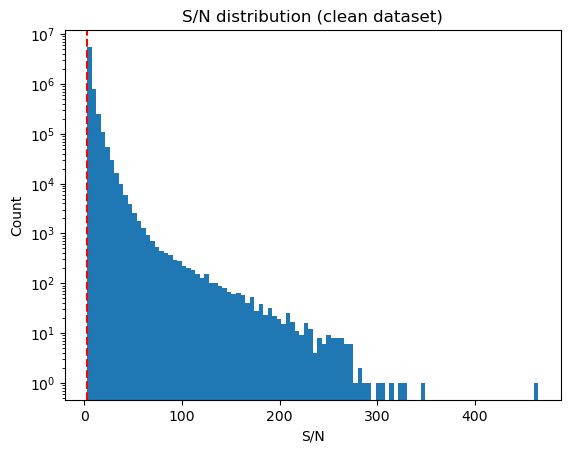

In [19]:
import matplotlib.pyplot as plt

sn_all = []
for f in files:
    sn_all.append(np.load(f)["sn"])
sn_all = np.concatenate(sn_all)

plt.hist(sn_all, bins=100)
plt.axvline(3, color="r", linestyle="--")
plt.xlabel("S/N")
plt.ylabel("Count")
plt.yscale("log")
plt.title("S/N distribution (clean dataset)")
plt.show()


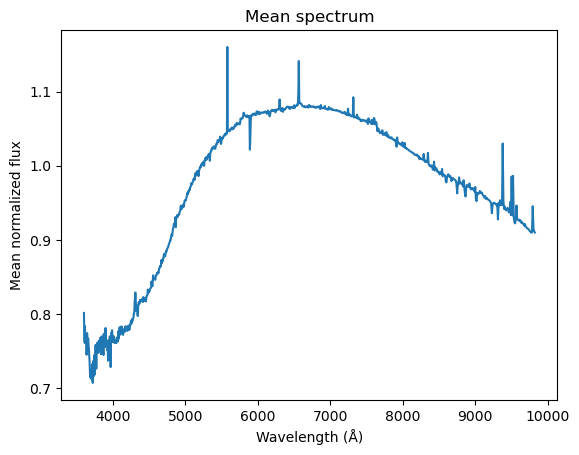

In [20]:
import numpy as np

wave = np.load(files[0])["wave_grid"]

mean_flux = np.zeros_like(wave)
count = 0

for f in files:
    X = np.load(f)["X"]
    mean_flux += X.sum(axis=0)
    count += X.shape[0]

mean_flux /= count

plt.plot(wave, mean_flux)
plt.xlabel("Wavelength (Å)")
plt.ylabel("Mean normalized flux")
plt.title("Mean spectrum")
plt.show()


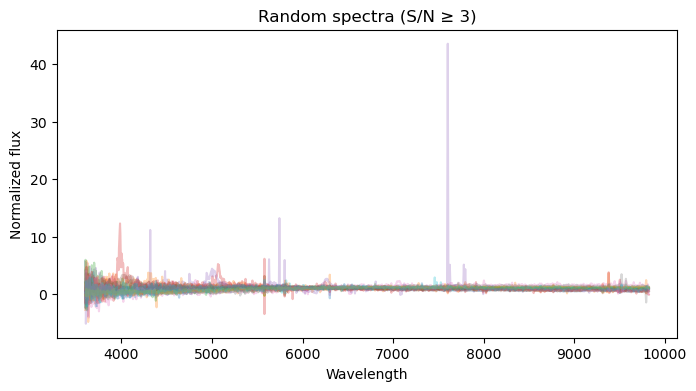

In [21]:
rng = np.random.default_rng(0)

plt.figure(figsize=(8,4))
for _ in range(20):
    f = rng.choice(files)
    d = np.load(f)
    i = rng.integers(0, len(d["TARGETID"]))
    plt.plot(wave, d["X"][i], alpha=0.3)

plt.xlabel("Wavelength")
plt.ylabel("Normalized flux")
plt.title("Random spectra (S/N ≥ 3)")
plt.show()


In [23]:
import os, glob, numpy as np

brz_files = glob.glob(os.path.join(brz_dir, "**", "*_brz.npz"), recursive=True)

total_raw = 0
for f in brz_files:
    d = np.load(f)
    total_raw += len(d["TARGETID"])

print("Total raw spectra:", total_raw)


Total raw spectra: 42605453


In [1]:
import numpy as np, glob, os
from tqdm import tqdm

brz_dir = "/global/cfs/cdirs/m4237/zixinq/data/dr2_catalog/galaxy_spectra_brz"

files = glob.glob(os.path.join(brz_dir, "**", "*.npz"), recursive=True)

total = 0
for f in files:
    d = np.load(f)
    total += len(d["TARGETID"])

print("Total raw spectra:", total)


sn_list = []

for fname in tqdm(files):
    path = os.path.join(brz_dir, fname)
    data = np.load(path)

    flux = data["flux_brz"]     
    ivar = data["ivar_brz"]     

    mask = (ivar > 0) & np.isfinite(flux)
    if mask.sum() == 0:
        continue

    sn = np.median(flux[mask] * np.sqrt(ivar[mask]))
    sn_list.append(sn)

sn_array = np.array(sn_list)

print("Number of spectra:", len(sn_array))
print("Median S/N:", np.median(sn_array))


Total raw spectra: 42605453


100%|██████████| 856/856 [3:23:52<00:00, 14.29s/it]  

Number of spectra: 856
Median S/N: 0.9427377


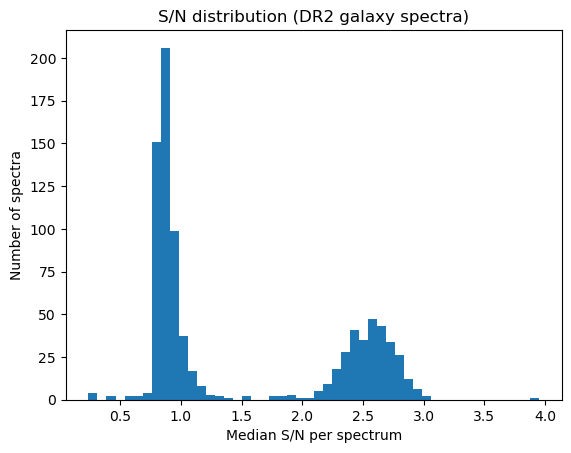

In [2]:
import matplotlib.pyplot as plt

plt.hist(sn_array, bins=50)
plt.xlabel("Median S/N per spectrum")
plt.ylabel("Number of spectra")
plt.title("S/N distribution (DR2 galaxy spectra)")
plt.show()


In [ ]:
#redshift preprocessing

In [1]:
import numpy as np

def make_z_lookup_arrays(loa_metadata):
    tid = np.asarray(loa_metadata["TARGETID"], dtype=np.int64)
    z   = np.asarray(loa_metadata["Z"], dtype=np.float32)

    # keep last occurrence if duplicates
    order = np.argsort(tid, kind="mergesort")
    tid_s = tid[order]
    z_s   = z[order]

    # for duplicates, keep the LAST one
    _, last_idx = np.unique(tid_s, return_index=False, return_counts=False), None
    # simpler: take unique on reversed array to keep last
    tid_r = tid_s[::-1]
    z_r   = z_s[::-1]
    uniq_tid_r, uniq_idx_r = np.unique(tid_r, return_index=True)
    # uniq_idx_r are positions in reversed arrays -> pick them, then reverse back sorted by tid
    keep_r = np.sort(uniq_idx_r)
    tid_u = tid_r[keep_r]
    z_u   = z_r[keep_r]
    # now sort by TARGETID
    order2 = np.argsort(tid_u)
    return tid_u[order2], z_u[order2]

def lookup_z_for_targetids(tid_query, tid_u, z_u):
    """Vectorized lookup; returns z with NaN for missing."""
    tid_query = np.asarray(tid_query, dtype=np.int64)
    idx = np.searchsorted(tid_u, tid_query)
    ok = (idx < tid_u.size) & (tid_u[idx] == tid_query)
    z = np.full(tid_query.shape, np.nan, dtype=np.float32)
    z[ok] = z_u[idx[ok]]
    return z

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from glob import glob
from tqdm import tqdm

def build_z_lookup(parquet_path, z_col="Z", tid_col="TARGETID"):
    df = pd.read_parquet(parquet_path, columns=[tid_col, z_col]).drop_duplicates(tid_col, keep="last")
    tid = df[tid_col].to_numpy(np.int64)
    z = df[z_col].to_numpy(np.float32)
    return dict(zip(tid, z))

def attach_z_to_prep_file(prep_npz_path, z_map, out_path=None, overwrite=False):
    d = np.load(prep_npz_path, allow_pickle=True)
    if "Z" in d.files and not overwrite:
        return None  # already has Z

    tid = d["TARGETID"].astype(np.int64, copy=False)
    z = np.fromiter((z_map.get(int(t), np.nan) for t in tid), dtype=np.float32, count=tid.size)

    if out_path is None:
        out_path = prep_npz_path
    tmp = out_path.replace(".npz", ".tmp.npz")

    payload = {k: d[k] for k in d.files}
    payload["Z"] = z

    np.savez(tmp, **payload)   # switch to np.savez_compressed if you want
    os.replace(tmp, out_path)
    return z

def attach_z_dir(prep_dir, meta_parquet, out_dir=None, pattern="*_prep_*.npz", overwrite=False):
    z_map = build_z_lookup(meta_parquet, z_col="Z", tid_col="TARGETID")
    files = sorted(glob(os.path.join(prep_dir, pattern)))
    if out_dir is not None:
        os.makedirs(out_dir, exist_ok=True)

    all_z = []
    n_missing = 0
    n_updated = 0

    for f in tqdm(files, desc="attach Z", unit="file"):
        out_path = os.path.join(out_dir, os.path.basename(f)) if out_dir else f
        z = attach_z_to_prep_file(f, z_map, out_path=out_path, overwrite=overwrite)
        if z is not None:
            n_updated += 1
            all_z.append(z)
            n_missing += int(np.isnan(z).sum())

    # If nothing was updated (because Z already existed), read Z back for plotting:
    if not all_z:
        zs = []
        for f in files:
            d = np.load(f, allow_pickle=True)
            if "Z" in d.files:
                zs.append(d["Z"].astype(np.float32, copy=False))
        all_z = zs

    z_cat = np.concatenate(all_z) if all_z else np.array([], dtype=np.float32)
    stats = {"n_files": len(files), "n_updated": n_updated, "n_missing_z": n_missing, "n_total_rows": int(z_cat.size)}
    return z_cat, stats


In [3]:
import os
import numpy as np
from glob import glob
from tqdm import tqdm

def attach_z_to_prep_file(prep_npz_path, tid_u, z_u, out_path=None, overwrite=False):
    d = np.load(prep_npz_path, allow_pickle=True)
    if ("Z" in d.files) and (not overwrite):
        return None  # already has Z

    tid = d["TARGETID"].astype(np.int64, copy=False)
    z   = lookup_z_for_targetids(tid, tid_u, z_u)

    if out_path is None:
        out_path = prep_npz_path

    tmp = out_path.replace(".npz", ".tmp.npz")
    payload = {k: d[k] for k in d.files}
    payload["Z"] = z

    np.savez(tmp, **payload)     # switch to np.savez_compressed if you prefer
    os.replace(tmp, out_path)
    return z

def attach_z_dir(prep_dir, tid_u, z_u, out_dir=None, pattern="*_prep_*.npz", overwrite=False):
    files = sorted(glob(os.path.join(prep_dir, "*_brz.npz")))
    if out_dir is not None:
        os.makedirs(out_dir, exist_ok=True)

    all_z = []
    n_missing = 0
    n_updated = 0

    for f in tqdm(files, desc="attach Z", unit="file"):
        out_path = os.path.join(out_dir, os.path.basename(f)) if out_dir else f
        z = attach_z_to_prep_file(f, tid_u, z_u, out_path=out_path, overwrite=overwrite)
        if z is not None:
            n_updated += 1
            all_z.append(z)
            n_missing += int(np.isnan(z).sum())

    # If nothing updated (already had Z), read Z for plotting:
    if not all_z:
        zs = []
        for f in files:
            d = np.load(f, allow_pickle=True)
            if "Z" in d.files:
                zs.append(d["Z"].astype(np.float32, copy=False))
        all_z = zs

    z_cat = np.concatenate(all_z) if all_z else np.array([], dtype=np.float32)
    stats = {"n_files": len(files), "n_updated": n_updated, "n_missing_z": n_missing, "n_total_rows": int(z_cat.size)}
    return z_cat, stats


In [4]:
import os, numpy as np
from glob import glob
from tqdm import tqdm

def attach_z_dir(brz_dir, tid_u, z_u, out_dir=None, overwrite=False, compress=False):
    files = sorted(glob(os.path.join(brz_dir, "*_brz.npz")))
    print("Found", len(files), "files")
    if out_dir is not None:
        os.makedirs(out_dir, exist_ok=True)

    save_fn = np.savez_compressed if compress else np.savez
    n_updated = 0
    n_missing = 0
    n_total = 0

    for f in tqdm(files, desc="attach Z", unit="file"):
        d = np.load(f, allow_pickle=True, mmap_mode="r")
        if ("Z" in d.files) and (not overwrite):
            continue

        tid = d["TARGETID"].astype(np.int64, copy=False)
        z = lookup_z_for_targetids(tid, tid_u, z_u)
        n_total += z.size
        n_missing += int(np.isnan(z).sum())

        out_path = os.path.join(out_dir, os.path.basename(f)) if out_dir else f
        tmp = out_path.replace(".npz", ".tmp.npz")

        # copy arrays without forcing them into RAM (mmap helps)
        payload = {k: d[k] for k in d.files}
        payload["Z"] = z

        save_fn(tmp, **payload)
        os.replace(tmp, out_path)
        n_updated += 1

    return {"n_files": len(files), "n_updated": n_updated, "n_total_rows": n_total, "n_missing_z": n_missing}


In [5]:
import matplotlib.pyplot as plt
import numpy as np

def plot_z_distribution(z, bins=120, title="Redshift (Z) distribution"):
    z = z[np.isfinite(z)]
    plt.figure()
    plt.hist(z, bins=bins)
    plt.xlabel("Z")
    plt.ylabel("Count")
    plt.title(title)
    plt.tight_layout()
    plt.show()


In [2]:
import logging
import os
import sys
from io import BytesIO
import pandas as pd
import requests
from datetime import date, timedelta, datetime
from collections import Counter
import numpy as np
import json
from astroquery.vizier import Vizier
import astropy.units as u
from astropy.io import fits
from astropy.coordinates import SkyCoord
from tqdm import tqdm
import time
from astropy.table import Table, Column, vstack, join
import re
from astropy.time import Time
from glob import glob
from multiprocessing import Pool

from desispec.io import read_spectra
from desitrip.preproc import rebin_flux, rescale_flux
from desispec.coaddition import coadd_cameras
from desiutil.depend import Dependencies
from scipy.ndimage import gaussian_filter1d

In [3]:
def load_metadata_table(file_path):
    """Load the FASTSPEC table from a FITS file."""
    with fits.open(file_path) as hdul:
        return Table(hdul['METADATA'].data)

In [ ]:
loa_path = "/global/cfs/cdirs/desi/vac/dr2/fastspecfit/loa/v1.0/catalogs"
fastspec_files = np.sort(glob(os.path.join(loa_path, "*.fits")))
loa_metadata = vstack([load_metadata_table(os.path.join(loa_path, i)) for i in fastspec_files])

In [ ]:
# loa_metadata already exists from your vstack(...)
tid_u, z_u = make_z_lookup_arrays(loa_metadata)

prep_dir = "/global/cfs/cdirs/m4237/zixinq/data/dr2_catalog/galaxy_spectra_brz"
out_dir ="/global/cfs/cdirs/m4237/zixinq/data/dr2_catalog/galaxy_spectra_restframe"

ret = attach_z_dir(prep_dir, tid_u, z_u, out_dir=out_dir, overwrite=False)

In [ ]:
print(ret)

read Z: 100%|██████████| 856/856 [01:52<00:00,  7.63file/s]


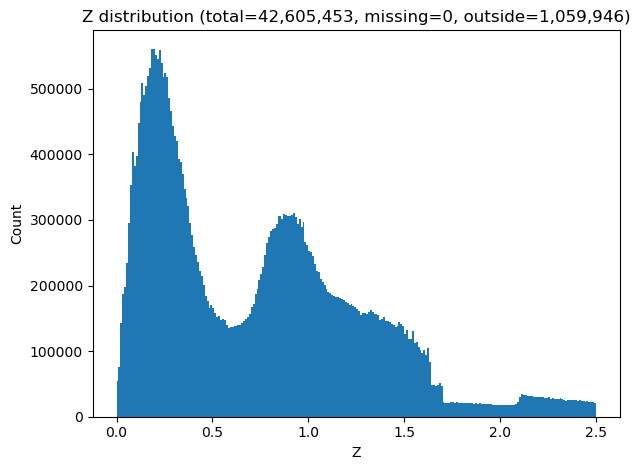

{'n_files': 856, 'n_total': 42605453, 'n_missing': 0, 'n_outside': 1059946}


In [12]:
import os
import numpy as np
import matplotlib.pyplot as plt
from glob import glob
from tqdm import tqdm

def plot_z_from_dir_streaming(npz_dir, pattern="*_brz.npz", zmax=2.5, bins=250):
    files = sorted(glob(os.path.join(npz_dir, pattern)))
    edges = fnp.linspace(0.0, zmax, bins + 1, dtype=np.float64)
    hist = np.zeros(bins, dtype=np.int64)

    n_total = 0
    n_missing = 0
    n_outside = 0

    for f in tqdm(files, desc="read Z", unit="file"):
        d = np.load(f, mmap_mode="r")
        z = d["Z"].astype(np.float32, copy=False)

        n_total += z.size
        good = np.isfinite(z)
        n_missing += int((~good).sum())

        zz = z[good]
        outside = (zz < edges[0]) | (zz > edges[-1])
        n_outside += int(outside.sum())
        zz = zz[~outside]

        h, _ = np.histogram(zz, bins=edges)
        hist += h

    centers = 0.5 * (edges[:-1] + edges[1:])

    plt.figure()
    plt.bar(centers, hist, width=(edges[1] - edges[0]), align="center")
    plt.xlabel("Z")
    plt.ylabel("Count")
    plt.title(f"Z distribution (total={n_total:,}, missing={n_missing:,}, outside={n_outside:,})")
    plt.tight_layout()
    plt.show()

    return {"n_files": len(files), "n_total": n_total, "n_missing": n_missing, "n_outside": n_outside}

out_dir = "/global/cfs/cdirs/m4237/zixinq/data/dr2_catalog/galaxy_spectra_restframe"
stats_plot = plot_z_from_dir_streaming(out_dir, pattern="*_brz.npz", zmax=2.5, bins=250)
print(stats_plot)

In [13]:
import os
import numpy as np

def build_loglam_grid(wave_in, nbins=1000):
    wmin = float(np.nanmin(wave_in))
    wmax = float(np.nanmax(wave_in))
    loglam = np.linspace(np.log10(wmin), np.log10(wmax), nbins, dtype=np.float64)
    return (10**loglam).astype(np.float32)

def rebin_interp_1d(wave_in, y_in, wave_out):
    good = np.isfinite(y_in) & np.isfinite(wave_in)
    if good.sum() < 2:
        return np.full_like(wave_out, np.nan, dtype=np.float32), np.zeros_like(wave_out, dtype=bool)
    y_out = np.interp(wave_out, wave_in[good], y_in[good], left=np.nan, right=np.nan).astype(np.float32)
    ok = np.isfinite(y_out)
    return y_out, ok

def spectrum_snr_scalar(flux, ivar):
    """
    Scalar S/N per spectrum.
    Define per-pixel sn = flux * sqrt(ivar); use robust median over valid pixels.
    """
    valid = np.isfinite(flux) & np.isfinite(ivar) & (ivar > 0)
    if valid.sum() < 10:
        return np.float32(np.nan)
    sn_pix = flux[valid] * np.sqrt(ivar[valid])
    # robust central tendency; absolute can be used if you want pure "amplitude" S/N
    return np.float32(np.nanmedian(sn_pix))


In [14]:
def preprocess_brz_file(
    npz_in,
    npz_out,
    nbins=1000,
    sn_min=3.0,
    compress=False,
):
    d = np.load(npz_in, allow_pickle=True, mmap_mode="r")

    targetid = d["TARGETID"].astype(np.int64, copy=False)
    z = d["Z"].astype(np.float32, copy=False) if "Z" in d.files else None

    wave_in = d["wave_brz"].astype(np.float32, copy=False)     # (L,)
    flux_in = d["flux_brz"]                                    # (N,L) memmap
    ivar_in = d["ivar_brz"]                                    # (N,L) memmap

    N, L = flux_in.shape
    assert ivar_in.shape == (N, L)

    wave_out = build_loglam_grid(wave_in, nbins=nbins)

    # 1) compute scalar S/N for each spectrum (native pixels; avoids rebin cost for rejects)
    sn = np.empty(N, dtype=np.float32)
    keep = np.zeros(N, dtype=bool)

    for i in range(N):
        f = flux_in[i]
        w = ivar_in[i]
        # bad pixels excluded inside spectrum_snr_scalar
        sni = spectrum_snr_scalar(f, w)
        sn[i] = sni
        keep[i] = np.isfinite(sni) and (sni >= sn_min)

    idx = np.nonzero(keep)[0]
    M = idx.size

    # If nothing passes, still write a tiny file for bookkeeping
    if M == 0:
        os.makedirs(os.path.dirname(npz_out) or ".", exist_ok=True)
        save_fn = np.savez_compressed if compress else np.savez
        tmp = npz_out.replace(".npz", ".tmp.npz")
        payload = dict(
            TARGETID=targetid[:0],
            Z=(z[:0] if z is not None else np.empty((0,), np.float32)),
            wave_grid=wave_out,
            X=np.empty((0, nbins), np.float32),
            W=np.empty((0, nbins), np.float32),
            norm=np.empty((0,), np.float32),
            SNR=np.empty((0,), np.float32),
            keep_mask=keep,   # optional: keep mask for original order
            sn_min=np.float32(sn_min),
        )
        save_fn(tmp, **payload)
        os.replace(tmp, npz_out)
        return {"N_in": int(N), "N_keep": 0}

    # 2) rebin + normalize only kept spectra
    X = np.empty((M, nbins), dtype=np.float32)
    W = np.empty((M, nbins), dtype=np.float32)
    norm = np.empty(M, dtype=np.float32)

    out_targetid = targetid[idx]
    out_z = z[idx] if z is not None else None
    out_sn = sn[idx]

    for j, i in enumerate(idx):
        f = flux_in[i].astype(np.float32, copy=False)
        w = ivar_in[i].astype(np.float32, copy=False)

        bad = (~np.isfinite(f)) | (~np.isfinite(w)) | (w <= 0)
        f2 = f.copy()
        f2[bad] = np.nan
        w2 = w.copy()
        w2[bad] = np.nan

        # rebin flux
        f_out, ok = rebin_interp_1d(wave_in, f2, wave_out)

        # rebin ivar (approx via interp)
        w_out, ok_w = rebin_interp_1d(wave_in, w2, wave_out)
        w_out = np.where(np.isfinite(w_out) & ok, w_out, 0.0).astype(np.float32)

        # normalize by median flux on valid pixels (post-rebin)
        valid = np.isfinite(f_out) & (w_out > 0)
        s = np.nanmedian(f_out[valid]) if np.any(valid) else np.nan
        if not np.isfinite(s) or s == 0:
            s = 1.0

        f_norm = (f_out / s).astype(np.float32)
        X[j] = np.where(np.isfinite(f_norm), f_norm, 0.0)
        W[j] = w_out
        norm[j] = np.float32(s)

    # 3) save
    os.makedirs(os.path.dirname(npz_out) or ".", exist_ok=True)
    save_fn = np.savez_compressed if compress else np.savez
    tmp = npz_out.replace(".npz", ".tmp.npz")

    payload = dict(
        TARGETID=out_targetid,
        wave_grid=wave_out,
        X=X,
        W=W,
        norm=norm,
        SNR=out_sn,
        sn_min=np.float32(sn_min),
    )
    if out_z is not None:
        payload["Z"] = out_z

    save_fn(tmp, **payload)
    os.replace(tmp, npz_out)

    return {"N_in": int(N), "N_keep": int(M)}

In [16]:
from glob import glob
from tqdm import tqdm

def preprocess_brz_dir(brz_dir, out_dir, nbins=1000, sn_min=3.0, compress=False, skip_existing=True):
    os.makedirs(out_dir, exist_ok=True)
    files = sorted(glob(os.path.join(brz_dir, "*_brz.npz")))
    print("Found", len(files), "BRZ files")

    tot_in = 0
    tot_keep = 0

    for f in tqdm(files, desc="preprocess", unit="file"):
        base = os.path.basename(f).replace("_brz.npz", "")
        out = os.path.join(out_dir, f"{base}_preprocess.npz")
        if skip_existing and os.path.exists(out):
            continue
        stats = preprocess_brz_file(f, out, nbins=nbins, sn_min=sn_min, compress=compress)
        tot_in += stats["N_in"]
        tot_keep += stats["N_keep"]

    print(f"Total kept: {tot_keep:,} / {tot_in:,}  ({(tot_keep/tot_in if tot_in else 0):.3%})")

In [ ]:
brz_dir  = "/global/cfs/cdirs/m4237/zixinq/data/dr2_catalog/galaxy_spectra_restframe"     
prep_out = "/global/cfs/cdirs/m4237/zixinq/data/dr2_catalog/galaxy_spectra_restframe"

preprocess_brz_dir(brz_dir, prep_out, nbins=1000, sn_min=3.0, compress=False, skip_existing=True)

In [1]:
import os
import numpy as np

def _coerce_wave_1d(wave):
    wave = np.asarray(wave)
    if wave.ndim == 1:
        return wave.astype(np.float32, copy=False)
    if wave.ndim == 2:
        w0 = wave[0]
        diff = np.nanmax(np.abs(wave - w0))
        if np.isfinite(diff) and diff == 0:
            return w0.astype(np.float32, copy=False)
        return np.nanmedian(wave, axis=0).astype(np.float32, copy=False)
    raise ValueError(f"wave must be 1D or 2D, got shape {wave.shape}")

def build_loglam_grid(wave_in, nbins=1000):
    wmin = float(np.nanmin(wave_in))
    wmax = float(np.nanmax(wave_in))
    loglam = np.linspace(np.log10(wmin), np.log10(wmax), nbins, dtype=np.float64)
    return (10**loglam).astype(np.float32)

def rebin_interp_1d(wave_in, y_in, wave_out):
    good = np.isfinite(y_in) & np.isfinite(wave_in)
    if good.sum() < 2:
        return np.full_like(wave_out, np.nan, dtype=np.float32), np.zeros_like(wave_out, dtype=bool)
    y_out = np.interp(wave_out, wave_in[good], y_in[good], left=np.nan, right=np.nan).astype(np.float32)
    ok = np.isfinite(y_out)
    return y_out, ok

def spectrum_snr_scalar(flux, ivar):
    # force numeric
    flux = np.asarray(flux, dtype=np.float32)
    ivar = np.asarray(ivar, dtype=np.float32)
    valid = np.isfinite(flux) & np.isfinite(ivar) & (ivar > 0)
    if valid.sum() < 10:
        return np.float32(np.nan)
    sn_pix = flux[valid] * np.sqrt(ivar[valid])
    return np.float32(np.nanmedian(sn_pix))

def _row_as_float32(a, i):
    # Handles object arrays where each row may be list/ndarray
    return np.asarray(a[i], dtype=np.float32)

def preprocess_transients_arrays(
    wave_in,
    flux_in,
    ivar_in,
    z_all=None,
    TYPE=None,
    out_npz=None,
    nbins=1000,
    sn_min=3.0,
    compress=False,
    save_keep_mask=True,
):
    wave_in = _coerce_wave_1d(wave_in)

    flux_in = np.asarray(flux_in)   # may be object; that's OK
    ivar_in = np.asarray(ivar_in)

    # Determine N, L robustly (supports object arrays of rows)
    if flux_in.ndim == 2:
        N, L = flux_in.shape
    elif flux_in.ndim == 1:
        N = flux_in.shape[0]
        L = np.asarray(flux_in[0]).shape[0]
    else:
        raise ValueError(f"flux_in must be (N,L) or (N,) of rows, got {flux_in.shape}")

    if wave_in.shape[0] != L:
        raise ValueError(f"wave_in must have length L={L}, got {wave_in.shape}")

    # Ensure monotonic wave; if we reorder wave, we must reorder each row too.
    order = None
    if not np.all(np.diff(wave_in) > 0):
        order = np.argsort(wave_in)
        wave_in = wave_in[order]

    wave_out = build_loglam_grid(wave_in, nbins=nbins)

    # 1) scalar S/N on native pixels
    sn = np.empty(N, dtype=np.float32)
    keep = np.zeros(N, dtype=bool)
    for i in range(N):
        f = _row_as_float32(flux_in, i)
        w = _row_as_float32(ivar_in, i)
        if order is not None:
            f = f[order]
            w = w[order]
        sni = spectrum_snr_scalar(f, w)
        sn[i] = sni
        keep[i] = np.isfinite(sni) and (sni >= sn_min)

    idx = np.nonzero(keep)[0]
    M = idx.size

    if M == 0:
        if out_npz is not None:
            os.makedirs(os.path.dirname(out_npz) or ".", exist_ok=True)
            save_fn = np.savez_compressed if compress else np.savez
            tmp = out_npz.replace(".npz", ".tmp.npz")
            payload = dict(
                wave_grid=wave_out,
                X=np.empty((0, nbins), np.float32),
                W=np.empty((0, nbins), np.float32),
                norm=np.empty((0,), np.float32),
                SNR=np.empty((0,), np.float32),
                sn_min=np.float32(sn_min),
            )
            if z_all is not None:
                payload["Z"] = np.asarray(z_all)[:0].astype(np.float32, copy=False)
            if TYPE is not None:
                payload["TYPE"] = np.asarray(TYPE)[:0]
            if save_keep_mask:
                payload["keep_mask"] = keep
            save_fn(tmp, **payload)
            os.replace(tmp, out_npz)
        return {"N_in": int(N), "N_keep": 0}

    # 2) rebin + normalize kept
    X = np.empty((M, nbins), dtype=np.float32)
    W = np.empty((M, nbins), dtype=np.float32)
    norm = np.empty(M, dtype=np.float32)

    out_sn = sn[idx]
    out_z = np.asarray(z_all)[idx].astype(np.float32, copy=False) if z_all is not None else None
    out_TYPE = np.asarray(TYPE)[idx] if TYPE is not None else None

    for j, i in enumerate(idx):
        f = _row_as_float32(flux_in, i)
        w = _row_as_float32(ivar_in, i)
        if order is not None:
            f = f[order]
            w = w[order]

        bad = (~np.isfinite(f)) | (~np.isfinite(w)) | (w <= 0)
        f2 = f.copy(); f2[bad] = np.nan
        w2 = w.copy(); w2[bad] = np.nan

        f_out, ok_f = rebin_interp_1d(wave_in, f2, wave_out)
        w_out, _ = rebin_interp_1d(wave_in, w2, wave_out)
        w_out = np.where(np.isfinite(w_out) & ok_f, w_out, 0.0).astype(np.float32)

        valid = np.isfinite(f_out) & (w_out > 0)
        s = np.nanmedian(f_out[valid]) if np.any(valid) else np.nan
        if not np.isfinite(s) or s == 0:
            s = 1.0

        f_norm = (f_out / s).astype(np.float32)
        X[j] = np.where(np.isfinite(f_norm), f_norm, 0.0)
        W[j] = w_out
        norm[j] = np.float32(s)

    if out_npz is not None:
        os.makedirs(os.path.dirname(out_npz) or ".", exist_ok=True)
        save_fn = np.savez_compressed if compress else np.savez
        tmp = out_npz.replace(".npz", ".tmp.npz")

        payload = dict(
            wave_grid=wave_out,
            X=X,
            W=W,
            norm=norm,
            SNR=out_sn,
            sn_min=np.float32(sn_min),
        )
        if out_z is not None:
            payload["Z"] = out_z
        if out_TYPE is not None:
            payload["TYPE"] = out_TYPE
        if save_keep_mask:
            payload["keep_mask"] = keep

        save_fn(tmp, **payload)
        os.replace(tmp, out_npz)

    return {"N_in": int(N), "N_keep": int(M)}

In [8]:
stats = preprocess_transients_arrays(
    wave_in=tr_coadd_wave_classified,
    flux_in=tr_coadd_flux_classified,
    ivar_in=tr_coadd_ivar_classified,
    z_all=z_all,
    TYPE=TYPE,
    out_npz=out_npz,
    nbins=1000,
    sn_min=3.0,
    compress=True,
    save_keep_mask=True,
)
print(stats)

{'N_in': 179, 'N_keep': 155}


In [52]:
import numpy as np
from desitrip.preproc import rebin_flux, rescale_flux

import numpy as np
from desitrip.preproc import rebin_flux, rescale_flux


def preprocess_transients_arrays(
    flux_in,
    wave_in,
    ivar_in,
    targetid=None,
    spectype=None,
    nbins=1000,
    minwave=3600.0,
    maxwave=9800.0,
    log=True,
    use_redshift=False,
    z_in=None,
):
    flux_in = np.asarray(flux_in, dtype=np.float32)
    wave_in = np.asarray(wave_in, dtype=np.float32)
    ivar_in = np.asarray(ivar_in, dtype=np.float32)

    if flux_in.ndim != 2:
        raise ValueError(f"flux_in must be 2D, got {flux_in.shape}")
    if ivar_in.shape != flux_in.shape:
        raise ValueError(f"ivar_in shape {ivar_in.shape} != flux_in shape {flux_in.shape}")

    N, L = flux_in.shape

    # Accept either common 1D wave grid or per-spectrum 2D wave grid
    if wave_in.ndim == 1:
        if wave_in.shape[0] != L:
            raise ValueError(f"wave_in shape {wave_in.shape} incompatible with flux_in shape {flux_in.shape}")
        wave_mode = "shared"
    elif wave_in.ndim == 2:
        if wave_in.shape != flux_in.shape:
            raise ValueError(f"wave_in shape {wave_in.shape} incompatible with flux_in shape {flux_in.shape}")
        wave_mode = "per_spectrum"
    else:
        raise ValueError(f"wave_in must be 1D or 2D, got shape {wave_in.shape}")

    if targetid is None:
        targetid = np.arange(N, dtype=np.int64)
    else:
        targetid = np.asarray(targetid)
        if len(targetid) != N:
            raise ValueError(f"targetid length {len(targetid)} != N={N}")

    if spectype is not None and len(spectype) != N:
        raise ValueError(f"spectype length {len(spectype)} != N={N}")

    if use_redshift:
        if z_in is None:
            raise ValueError("use_redshift=True but z_in is None")
        z_in = np.asarray(z_in, dtype=np.float32)
        if len(z_in) != N:
            raise ValueError(f"z_in length {len(z_in)} != N={N}")
    else:
        z_in = None

    # Original native-grid S/N
    valid_native = np.isfinite(flux_in) & np.isfinite(ivar_in) & (ivar_in > 0)
    if wave_mode == "shared":
        valid_native &= np.isfinite(wave_in)[None, :]
    else:
        valid_native &= np.isfinite(wave_in)

    snr_orig = np.zeros(N, dtype=np.float32)
    for i in range(N):
        if np.any(valid_native[i]):
            vals = np.abs(flux_in[i, valid_native[i]]) * np.sqrt(ivar_in[i, valid_native[i]])
            snr_orig[i] = np.float32(np.median(vals))

    # Full outputs
    wave_grid = (
        np.logspace(np.log10(minwave), np.log10(maxwave), nbins).astype(np.float32)
        if log else
        np.linspace(minwave, maxwave, nbins).astype(np.float32)
    )
    X = np.zeros((N, nbins), dtype=np.float32)
    W = np.zeros((N, nbins), dtype=np.float32)
    M = np.zeros((N, nbins), dtype=np.uint8)
    norm = np.ones(N, dtype=np.float32)

    # For per-spectrum wave grids, row-by-row rebinning is simplest and robust.
    # For shared wave grids, batch rebinning is fine.
    if wave_mode == "shared":
        flux_work = flux_in.copy()
        ivar_work = ivar_in.copy()

        bad = (~np.isfinite(flux_work)) | (~np.isfinite(ivar_work)) | (ivar_work <= 0)
        flux_work[bad] = 0.0
        ivar_work[bad] = 0.0

        keep_rows = np.count_nonzero(flux_work, axis=1) > 0
        nkeep = int(np.sum(keep_rows))

        if nkeep > 0:
            flux_keep = flux_work[keep_rows]
            ivar_keep = ivar_work[keep_rows]
            z_keep = z_in[keep_rows] if z_in is not None else None

            rewave, f_keep, w_keep = rebin_flux(
                wave=wave_in,
                flux=flux_keep,
                ivar=ivar_keep,
                z=z_keep,
                minwave=minwave,
                maxwave=maxwave,
                nbins=nbins,
                log=log,
                clip=False,
            )

            wave_grid = np.asarray(rewave, dtype=np.float32)
            out_rows = np.flatnonzero(keep_rows)

            for j, i in enumerate(out_rows):
                valid = np.isfinite(f_keep[j]) & np.isfinite(w_keep[j]) & (w_keep[j] > 0)
                if not np.any(valid):
                    continue

                fv = f_keep[j, valid]
                wv = w_keep[j, valid]

                fmin = np.min(fv)
                fmax = np.max(fv)
                scale = fmax - fmin

                if np.isfinite(scale) and scale > 0:
                    X[i, valid] = rescale_flux(fv).astype(np.float32)
                    W[i, valid] = (wv * (scale ** 2)).astype(np.float32)
                    norm[i] = np.float32(scale)
                else:
                    X[i, valid] = 0.0
                    W[i, valid] = 0.0
                    norm[i] = 1.0

                M[i, valid] = 1

    else:
        # Per-spectrum wavelength arrays
        for i in range(N):
            wi = wave_in[i].copy()
            fi = flux_in[i].copy()
            vi = ivar_in[i].copy()

            bad = (~np.isfinite(wi)) | (~np.isfinite(fi)) | (~np.isfinite(vi)) | (vi <= 0)
            wi = wi[~bad]
            fi = fi[~bad]
            vi = vi[~bad]

            if wi.size < 2:
                continue

            # Ensure increasing wavelength order
            order = np.argsort(wi)
            wi = wi[order]
            fi = fi[order]
            vi = vi[order]

            # Remove duplicate wavelengths if present
            uniq = np.diff(wi, prepend=wi[0] - 1) > 0
            wi = wi[uniq]
            fi = fi[uniq]
            vi = vi[uniq]

            if wi.size < 2:
                continue

            z_i = z_in[i] if z_in is not None else None

            rewave, f_out, w_out = rebin_flux(
                wave=wi,
                flux=fi,
                ivar=vi,
                z=z_i,
                minwave=minwave,
                maxwave=maxwave,
                nbins=nbins,
                log=log,
                clip=False,
            )

            wave_grid = np.asarray(rewave, dtype=np.float32)
            valid = np.isfinite(f_out) & np.isfinite(w_out) & (w_out > 0)

            if not np.any(valid):
                continue

            fv = f_out[valid]
            wv = w_out[valid]

            fmin = np.min(fv)
            fmax = np.max(fv)
            scale = fmax - fmin

            if np.isfinite(scale) and scale > 0:
                X[i, valid] = rescale_flux(fv).astype(np.float32)
                W[i, valid] = (wv * (scale ** 2)).astype(np.float32)
                norm[i] = np.float32(scale)
            else:
                X[i, valid] = 0.0
                W[i, valid] = 0.0
                norm[i] = 1.0

            M[i, valid] = 1

    valid_frac = M.mean(axis=1).astype(np.float32)

    snr_proxy = np.zeros(N, dtype=np.float32)
    for i in range(N):
        valid = M[i] > 0
        if np.any(valid):
            vals = np.abs(X[i, valid]) * np.sqrt(W[i, valid])
            snr_proxy[i] = np.float32(np.median(vals))

    keep_train = ((valid_frac >= 0.9) & (snr_orig >= 3.0)).astype(np.uint8)

    out = dict(
        TARGETID=targetid,
        wave_grid=wave_grid,
        X=X,
        W=W,
        M=M,
        norm=norm,
        valid_frac=valid_frac,
        snr_orig=snr_orig,
        snr_proxy=snr_proxy,
        keep_train=keep_train,
    )

    if spectype is not None:
        out["SPECTYPE"] = spectype

    if spectype is not None:
        out["TARGETID"] = targetid

    return out

In [53]:
prep = preprocess_transients_arrays(
    flux_in=tr_coadd_flux_classified,
    wave_in=tr_coadd_wave_classified,
    ivar_in=tr_coadd_ivar_classified,
    targetid=tr_targetid,
    spectype=tr_type,
    nbins=1000,
    minwave=3600.0,
    maxwave=9800.0,
    log=True,
    use_redshift=False,
)

In [50]:
'''
transients_classified = np.load(
    "/global/cfs/cdirs/m4237/zixinq/data/new/transient_coadd_fluxes_classified.npz",
    allow_pickle=True,
)
'''

transients_classified = np.load("/global/cfs/cdirs/desi/users/zixinq/data/dr2_catalog/transient_catalog.npz", allow_pickle = True,)

tr_coadd_flux_classified = transients_classified["coadd_flux"]
tr_coadd_wave_classified = transients_classified["coadd_wave"]
tr_coadd_ivar_classified = transients_classified["coadd_ivar"]
tr_type = transients_classified["TYPE"]
tr_targetid = transients_classified["TARGETID"]

print(tr_coadd_flux_classified.shape)
print(tr_coadd_wave_classified.shape)
print(tr_coadd_ivar_classified.shape)

(783, 7781)
(783, 7781)
(783, 7781)


In [54]:
np.savez(
    "/global/cfs/cdirs/desi/users/zixinq/data/dr2_catalog/transients_preprocess.npz",
    **prep
)

In [11]:
np.savez(
    "/global/cfs/cdirs/desi/users/zixinq/data/dr2_catalog/transient_spectra_preprocess.npz",
    **prep
)

In [25]:
import os
from glob import glob

import numpy as np
from tqdm import tqdm

# assumes you already have rebin_interp_1d(wave_in, y_in, wave_out) in scope

def add_mask_to_preprocessed_one(pre_npz, brz_npz, overwrite=False, compress=False):
    dp = np.load(pre_npz, allow_pickle=True)
    if (not overwrite) and ("M" in dp.files):
        return False, 0

    tgt_p = dp["TARGETID"].astype(np.int64, copy=False)           # (M,)
    wave_out = dp["wave_grid"].astype(np.float32, copy=False)     # (nbins,)
    M_out, nbins = len(tgt_p), len(wave_out)

    db = np.load(brz_npz, allow_pickle=True, mmap_mode="r")
    if "mask_brz" not in db.files:
        raise RuntimeError(f"{brz_npz}: missing mask_brz")

    tgt_b = db["TARGETID"].astype(np.int64, copy=False)           # (N,)
    wave_in = db["wave_brz"].astype(np.float32, copy=False)       # (L,)
    mask_in = db["mask_brz"]                                      # (N, L) memmap

    # Map pre TARGETID -> brz row index (vectorized)
    order = np.argsort(tgt_b)
    tgt_sorted = tgt_b[order]
    pos = np.searchsorted(tgt_sorted, tgt_p)
    ok = (pos < len(tgt_sorted)) & (tgt_sorted[pos] == tgt_p)

    src_rows = np.full(M_out, -1, dtype=np.int64)
    src_rows[ok] = order[pos[ok]]

    # Output mask: uint8, 1=bad, 0=good
    M = np.ones((M_out, nbins), dtype=np.uint8)   # default bad if missing
    n_missing = int((src_rows < 0).sum())

    for j in range(M_out):
        i = src_rows[j]
        if i < 0:
            continue

        bad = (mask_in[i] != 0).astype(np.float32)  # 0/1 on input grid
        bad_out_f, ok_out = rebin_interp_1d(wave_in, bad, wave_out)

        # Conservative: any hint of bad -> bad
        bad_out = np.where(ok_out, (bad_out_f > 0.0), True)
        M[j] = bad_out.astype(np.uint8)

    # Rewrite npz with M added
    save_fn = np.savez_compressed if compress else np.savez
    tmp = pre_npz.replace(".npz", ".tmp.npz")

    payload = {k: dp[k] for k in dp.files}
    payload["M"] = M

    save_fn(tmp, **payload)
    os.replace(tmp, pre_npz)

    return True, n_missing


def patch_preprocessed_dir(pre_dir, brz_dir, pattern="*_prep_1000.npz",
                           compress=False, overwrite=False):
    files = sorted(glob(os.path.join(pre_dir, pattern)))
    if not files:
        raise RuntimeError(f"No files matched {pattern} in {pre_dir}")

    n_upd = n_skip = n_fail = 0
    total_missing = 0

    for pre_npz in tqdm(files, desc="patch preprocess masks", unit="file"):
        # base mapping: batch_XXXX_YYYYYY_prep_1000.npz -> batch_XXXX_YYYYYY_brz.npz
        base = os.path.basename(pre_npz).replace("_prep_1000.npz", "")
        brz_npz = os.path.join(brz_dir, base + "_brz.npz")

        if not os.path.exists(brz_npz):
            tqdm.write(f"[skip] missing brz: {os.path.basename(brz_npz)}")
            n_skip += 1
            continue

        try:
            updated, n_missing = add_mask_to_preprocessed_one(
                pre_npz, brz_npz, overwrite=overwrite, compress=compress
            )
            if updated:
                n_upd += 1
                total_missing += n_missing
            else:
                n_skip += 1
        except Exception as e:
            tqdm.write(f"[fail] {os.path.basename(pre_npz)}: {repr(e)}")
            n_fail += 1

    print(f"[done] updated={n_upd} skipped={n_skip} failed={n_fail} total_missing_TARGETID={total_missing}")

In [28]:
pre_dir = "/global/cfs/cdirs/m4237/zixinq/data/dr2_catalog/galaxy_preprocess_sn3"
brz_dir = "/global/cfs/cdirs/m4237/zixinq/data/dr2_catalog/galaxy_spectra/task_/brz"

patch_preprocessed_dir(pre_dir, brz_dir, pattern="*_prep_1000.npz", compress=False, overwrite=False)

patch preprocess masks: 100%|██████████| 856/856 [1:18:26<00:00,  5.50s/file]

[done] updated=856 skipped=0 failed=0 total_missing_TARGETID=0


KeyError: 'TYPE is not a file in the archive'

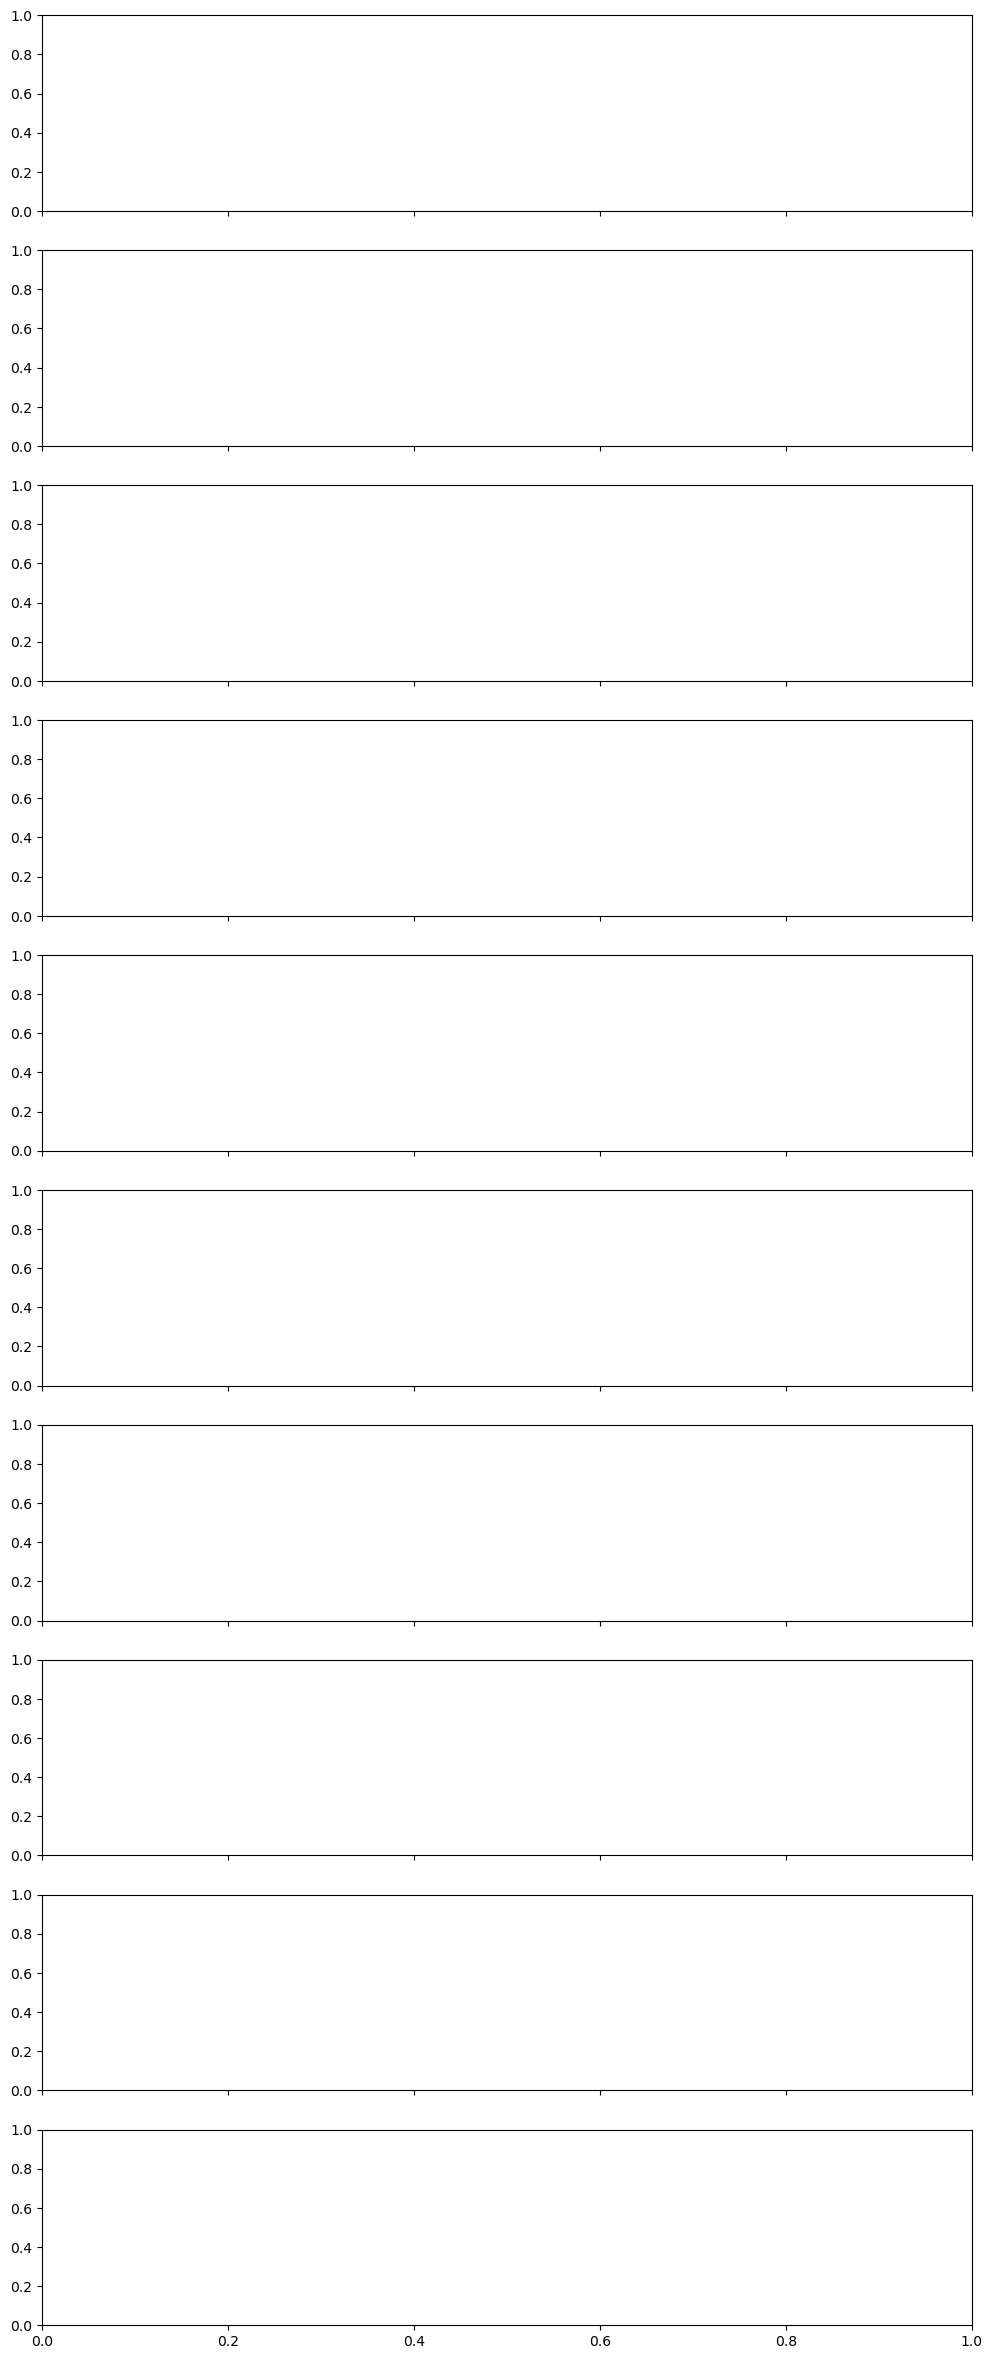

In [1]:
import numpy as np
import matplotlib.pyplot as plt

data = np.load("/global/cfs/cdirs/desi/users/zixinq/data/dr2_catalog/transients_preprocessed_all.npz", allow_pickle=True)

nplot = 10

fig, axes = plt.subplots(
    nplot, 1,
    figsize=(12, 3*nplot),
    sharex=True
)

for i, ax in enumerate(axes):
    wave = data["W"][i]
    flux = data["X"][i]

    targetid = data["TARGETID"][i]
    typ = data["TYPE"][i]
    z = data["Z"][i]
    night = data["NIGHT"][i]

    ax.plot(wave, flux, lw=0.8)

    ax.set_ylabel("Flux")
    ax.set_title(
        f"TARGETID={targetid} | {typ} | z={float(z):.4f} | NIGHT={night}"
    )

axes[-1].set_xlabel(r"Wavelength [$\AA$]")

plt.tight_layout()
plt.show()

In [72]:
import numpy as np
import pandas as pd

# Load datasets
base_npz = np.load("/global/cfs/cdirs/desi/users/zixinq/data/dr2_catalog/transient_spectra_preprocess/batch_0000_prep_1000.npz", allow_pickle=True)
trans_npz = np.load("/global/cfs/cdirs/desi/users/zixinq/data/dr2_catalog/transients_preprocess.npz", allow_pickle=True)

# Convert to normal dictionaries
base = {k: base_npz[k] for k in base_npz.files}
trans = {k: trans_npz[k] for k in trans_npz.files}

print("Base keys:", base.keys())
print("Transient keys:", trans.keys())

Base keys: dict_keys(['TARGETID', 'SPECTYPE', 'wave_grid', 'X', 'W', 'M', 'norm', 'valid_frac', 'snr_orig', 'snr_proxy', 'keep_train'])
Transient keys: dict_keys(['TARGETID', 'wave_grid', 'X', 'W', 'M', 'norm', 'valid_frac', 'snr_orig', 'snr_proxy', 'keep_train', 'SPECTYPE'])


In [74]:
import numpy as np

# 1. Load the npz file
data = np.load("/global/cfs/cdirs/desi/users/zixinq/data/dr2_catalog/transients_preprocess.npz",allow_pickle=True)

# 2. Access the specific key
array_data = data['SPECTYPE']

# 3. Get unique values and their corresponding counts
values, counts = np.unique(array_data, return_counts=True)

# 4. Print the results together
for value, count in zip(values, counts):
    print(f"Value: {value} | Count: {count}")


Value: Host | Count: 244
Value: QSO | Count: 143
Value: SN II | Count: 77
Value: SN Ia | Count: 222
Value: SN Ib/c | Count: 24
Value: TDE | Count: 1
Value: Unknown | Count: 72


In [75]:
keep_types = ["SN Ia", "SN II", "SN Ib/c", "TDE"]

mask = np.isin(trans["SPECTYPE"], keep_types)

print("Keeping:", mask.sum(), "of", len(mask))

print(
    pd.Series(trans["SPECTYPE"][mask])
    .value_counts()
)

Keeping: 324 of 783
SN Ia      222
SN II       77
SN Ib/c     24
TDE          1
Name: count, dtype: int64


In [76]:
row_keys = [
    "TARGETID",
    "SPECTYPE",
    "X",
    "W",
    "M",
    "norm",
    "valid_frac",
    "snr_orig",
    "snr_proxy",
    "keep_train",
]

merged = {}

for key in row_keys:
    merged[key] = np.concatenate(
        [
            base[key],
            trans[key][mask]
        ],
        axis=0
    )

In [77]:
print(base["wave_grid"].shape)
print(trans["wave_grid"].shape)

print(
    "Same wavelength grid:",
    np.allclose(
        base["wave_grid"],
        trans["wave_grid"],
        equal_nan=True
    )
)

(1000,)
(1000,)
Same wavelength grid: True


In [78]:
print("\nMerged shapes:")

for key, value in merged.items():
    print(key, np.shape(value))


Merged shapes:
TARGETID (726,)
SPECTYPE (726,)
X (726, 1000)
W (726, 1000)
M (726, 1000)
norm (726,)
valid_frac (726,)
snr_orig (726,)
snr_proxy (726,)
keep_train (726,)


In [79]:
np.savez_compressed(
    "/global/cfs/cdirs/desi/users/zixinq/data/dr2_catalog/transients_preprocessed_all.npz",
    **merged
)

In [44]:
def simplify_label(label):
    if not isinstance(label, str):
        return "Unknown"
    label = label.lower()
    if "ia" in label:
        return "SN Ia"
    elif "ii" in label:
        return "SN II"
    elif "ib" in label or "ic" in label:
        return "SN Ib/c"
    elif "tde" in label:
        return "TDE"
    elif "agn" in label:
        return "AGN"
    elif "qso" in label or "quasar" in label:
        return "QSO"
    elif "gal" in label or "host" in label:
        return "Host"
    else:
        return "Unknown"

type_simple = pd.Series(my_array).apply(simplify_label).to_numpy()

print(pd.Series(type_simple).value_counts())

Host       244
SN Ia      222
QSO        143
SN II       77
Unknown     72
SN Ib/c     24
TDE          1
Name: count, dtype: int64


In [70]:
d_npz = np.load("/global/cfs/cdirs/desi/users/zixinq/data/dr2_catalog/transients_preprocess.npz", allow_pickle=True)

d = {key: d_npz[key] for key in d_npz.files}

d["SPECTYPE"] = (
    pd.Series(my_array)
    .apply(simplify_label)
    .to_numpy()
)

print(pd.Series(d["SPECTYPE"]).value_counts())

Host       244
SN Ia      222
QSO        143
SN II       77
Unknown     72
SN Ib/c     24
TDE          1
Name: count, dtype: int64


In [71]:
np.savez_compressed(
    "/global/cfs/cdirs/desi/users/zixinq/data/dr2_catalog/transients_preprocess.npz",
    **d
)